In [ ]:
import os

Mounted at /content/drive


In [ ]:
import tensorflow as tf
import numpy as np
from scipy.spatial.distance import cosine
# Importamos PRIMERO solo las librerías de TF/Keras que necesitamos
from transformers import AutoTokenizer
from models.bert_model import BertModel, load_weights_from_checkpoint

In [4]:
# ¡NO importamos sentence-transformers aquí todavía!

def mean_pooling(sequence_output, attention_mask):
    input_mask_expanded = tf.cast(tf.expand_dims(attention_mask, axis=-1), dtype=tf.float32)
    sum_embeddings = tf.reduce_sum(sequence_output * input_mask_expanded, axis=1)
    sum_mask = tf.clip_by_value(tf.reduce_sum(input_mask_expanded, axis=1), 1e-9, 1e9)
    return sum_embeddings / sum_mask

# --- Configuración ---
MODEL_NAME = 'prajjwal1/bert-tiny'
CHECKPOINT_PATH = 'BERT_tiny/bert_model.ckpt'
# LISTA DE ORACIONES OPTIMIZADA PARA CLUSTERING
# ENGLISH SENTENCES FOR A MONOLINGUAL MODEL
# CORPUS OF MAXIMALLY DISTINCT SENTENCES
SENTENCES = [
    # Topic 1: Quantum & Particle Physics (15 sentences)
    "The Higgs boson is responsible for giving elementary particles their mass.", "Quantum entanglement describes a state where particles are linked, regardless of distance.",
    "Quark-gluon plasma is a state of matter in quantum chromodynamics.", "A tokamak uses powerful magnetic fields to confine plasma for nuclear fusion.",
    "Neutrino oscillation implies that neutrinos have a non-zero mass.", "The Schrödinger equation is fundamental to the theory of quantum mechanics.",
    "Supersymmetry proposes a relationship between bosons and fermions.", "The Pauli exclusion principle states that two identical fermions cannot occupy the same quantum state.",
    "The Lamb shift is a small difference in energy between two levels in the hydrogen atom.", "Feynman diagrams are pictorial representations of mathematical expressions in particle physics.",
    "The half-life of a radionuclide is the time for half of the sample to decay.", "The Standard Model classifies all known elementary particles.",
    "Leptons and quarks are the fundamental constituents of matter.", "Beta decay is a type of radioactive decay in which a beta particle is emitted.",
    "The Large Hadron Collider (LHC) is the world's largest particle accelerator.",
    # Topic 2: Harry Potter Magic System (15 sentences, con la oración corregida)
    "The Patronus Charm conjures a magical guardian to repel Dementors.", "A Horcrux is a dark magical object used to achieve immortality.",
    "The Polyjuice Potion allows a person to assume the physical appearance of another.", "Apparition is the magical form of teleportation, requiring a license.",
    "Veritaserum is a powerful truth serum that forces the drinker to answer questions honestly.", "The Unforgivable Curses are Avada Kedavra, Crucio, and Imperio.",
    "A boggart is a shape-shifting creature that takes on the form of one's worst fear.", "The Elder Wand, the Resurrection Stone, and the Cloak of Invisibility form the Deathly Hallows.",
    "Occlumency is the magical art of defending one's mind from external intrusion.", "The spell 'Wingardium Leviosa' is used to make objects levitate.",
    "The Fidelius Charm is a complex spell used to hide a secret within a person's soul.", # <-- LA ORACIÓN CORREGIDA
    "Animagi are wizards who can transform themselves into an animal at will.", "The 'Expecto Patronum' incantation is crucial for casting a Patronus.",
    "Transfiguration is the branch of magic that focuses on altering the form of objects.", "The Mirror of Erised shows the deepest, most desperate desire of our hearts.", # <-- Reemplazamos la oración del portkey con dos fuertes
    # Topic 3: French Culinary Techniques (15 sentences)
    "A roux is a mixture of fat and flour used to thicken sauces.", "Braising involves searing meat at a high temperature, then simmering it in a covered pot.",
    "A mother sauce, like Béchamel or Velouté, is a base for many other sauces.", "To sauté is to cook food quickly in a minimal amount of fat over high heat.",
    "Mise en place is the culinary process of preparing all ingredients before starting to cook.", "A chiffonade is a slicing technique in which leafy greens are cut into long, thin strips.",
    "Deglazing is the process of adding liquid to a hot pan to lift caramelized bits off the bottom.", "An emulsion is a mixture of two liquids that would not normally mix, like oil and vinegar.",
    "Sous-vide is a method of cooking where food is sealed in a bag and cooked in a water bath.", "Consommé is a type of clear soup made from richly flavored stock.",
    "Flambé is a cooking procedure in which alcohol is added to a hot pan to create a burst of flames.", "A mirepoix is a flavor base made from diced vegetables cooked slowly in fat.",
    "The process of tempering chocolate ensures a glossy finish and a crisp snap.", "Pâté à choux is a light pastry dough used to make éclairs and cream puffs.",
    "Blanching involves briefly scalding vegetables in boiling water, then plunging them into ice water."
]


print("--- Prueba de Fuego: Comparación con SentenceTransformers ---")

print(f"\n1. Procesando con nuestro modelo 'from scratch' en un entorno TF limpio...")

tokenizer_hf = AutoTokenizer.from_pretrained(MODEL_NAME)

--- Prueba de Fuego: Comparación con SentenceTransformers ---

1. Procesando con nuestro modelo 'from scratch' en un entorno TF limpio...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

In [11]:
config = {
    'vocab_size': tokenizer_hf.vocab_size, 'max_position_embeddings': 512,
    'type_vocab_size': tokenizer_hf.model_max_length, # Usamos un valor de la config del tokenizer
    'hidden_size': 128, 'num_heads': 2, 'num_layers': 2, 'intermediate_size': 512,
    'dropout_rate': 0.0 # Dropout a 0 para inferencia determinista
}
from transformers import AutoConfig
hf_config = AutoConfig.from_pretrained(MODEL_NAME)
config['type_vocab_size'] = hf_config.type_vocab_size


bert_from_scratch = BertModel(config, name='bert')
bert_from_scratch_raw = BertModel(config, name='bert_raw')

In [12]:
hf_config.max_position_embeddings

512

In [13]:
hf_config.intermediate_size

512

In [14]:
# Forzar construcción y cargar los pesos validados
dummy_inputs = tokenizer_hf("test", return_tensors="pt")
_ = bert_from_scratch([dummy_inputs['input_ids'], dummy_inputs['token_type_ids']])

print("   Cargando pesos en nuestro modelo...")
load_weights_from_checkpoint(bert_from_scratch, CHECKPOINT_PATH)
bert_from_scratch.trainable = False

   Cargando pesos en nuestro modelo...

Cargados 39 de 39 pesos del modelo.


In [16]:
print("   Procesando oraciones con nuestro pipeline manual...")
inputs = tokenizer_hf(SENTENCES, padding=True, truncation=True, return_tensors='pt')
input_ids, token_type_ids, attention_mask = inputs['input_ids'], inputs['token_type_ids'], inputs['attention_mask']

_, sequence_output_scratch = bert_from_scratch([input_ids, token_type_ids], return_sequence=True)
_, sequence_output_scratch_raw = bert_from_scratch_raw([input_ids, token_type_ids], return_sequence=True)

pooled_embeddings_scratch = mean_pooling(sequence_output_scratch, attention_mask)
embeddings_scratch_normalized = tf.nn.l2_normalize(pooled_embeddings_scratch, axis=1).numpy()

pooled_embeddings_scratch_raw = mean_pooling(sequence_output_scratch_raw, attention_mask)
embeddings_scratch_normalized_raw = tf.nn.l2_normalize(pooled_embeddings_scratch_raw, axis=1).numpy()
print("   Embeddings de nuestro modelo generados. Shape:", embeddings_scratch_normalized.shape)

   Procesando oraciones con nuestro pipeline manual...
   Embeddings de nuestro modelo generados. Shape: (45, 128)


In [17]:
print(f"\n2. Cargando y procesando con SentenceTransformers...")

from sentence_transformers import SentenceTransformer
sbert_model = SentenceTransformer(MODEL_NAME)

print("   Codificando oraciones con SBERT...")
embeddings_sbert = sbert_model.encode(SENTENCES, normalize_embeddings=True)
print("   Embeddings de SBERT generados. Shape:", embeddings_sbert.shape)


2. Cargando y procesando con SentenceTransformers...


pytorch_model.bin:   0%|          | 0.00/17.8M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

   Codificando oraciones con SBERT...
   Embeddings de SBERT generados. Shape: (45, 128)


In [18]:
print("\n--- 3. Resultados de la Comparación ---")

for i, sentence in enumerate(SENTENCES):
    print(f"\nFrase: \"{sentence}\"")
    emb_sbert = embeddings_sbert[i]
    emb_scratch = embeddings_scratch_normalized[i]

    similarity = 1 - cosine(emb_sbert, emb_scratch)
    abs_diff = np.mean(np.abs(emb_sbert - emb_scratch))

    print(f"  Similitud Coseno: {similarity:.8f}")
    print(f"  Diferencia Absoluta Media: {abs_diff:.6e}")

    if np.allclose(emb_sbert, emb_scratch, atol=1e-5):
        print("  ✅ ¡ÉXITO TOTAL! El embedding final es idéntico.")
    else:
        print("  ❌ ¡Atención! Los embeddings finales difieren.")


--- 3. Resultados de la Comparación ---

Frase: "The Higgs boson is responsible for giving elementary particles their mass."
  Similitud Coseno: 0.99047202
  Diferencia Absoluta Media: 9.979913e-03
  ❌ ¡Atención! Los embeddings finales difieren.

Frase: "Quantum entanglement describes a state where particles are linked, regardless of distance."
  Similitud Coseno: 0.99543619
  Diferencia Absoluta Media: 6.645166e-03
  ❌ ¡Atención! Los embeddings finales difieren.

Frase: "Quark-gluon plasma is a state of matter in quantum chromodynamics."
  Similitud Coseno: 0.99849832
  Diferencia Absoluta Media: 3.661665e-03
  ❌ ¡Atención! Los embeddings finales difieren.

Frase: "A tokamak uses powerful magnetic fields to confine plasma for nuclear fusion."
  Similitud Coseno: 0.99581540
  Diferencia Absoluta Media: 6.441922e-03
  ❌ ¡Atención! Los embeddings finales difieren.

Frase: "Neutrino oscillation implies that neutrinos have a non-zero mass."
  Similitud Coseno: 0.99632567
  Diferencia Abso

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import umap

from matplotlib.lines import Line2D

In [20]:
embeddings_sbert = embeddings_sbert
embeddings_scratch = embeddings_scratch_normalized
embeddings_scratch_raw = embeddings_scratch_normalized_raw

In [21]:
n_sentences = len(SENTENCES)

Reduciendo dimensionalidad con UMAP...
Gráfico 1 (Lollipop) generado.
Generando heatmap de similitud...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Gráfico 2 (Heatmap) generado.


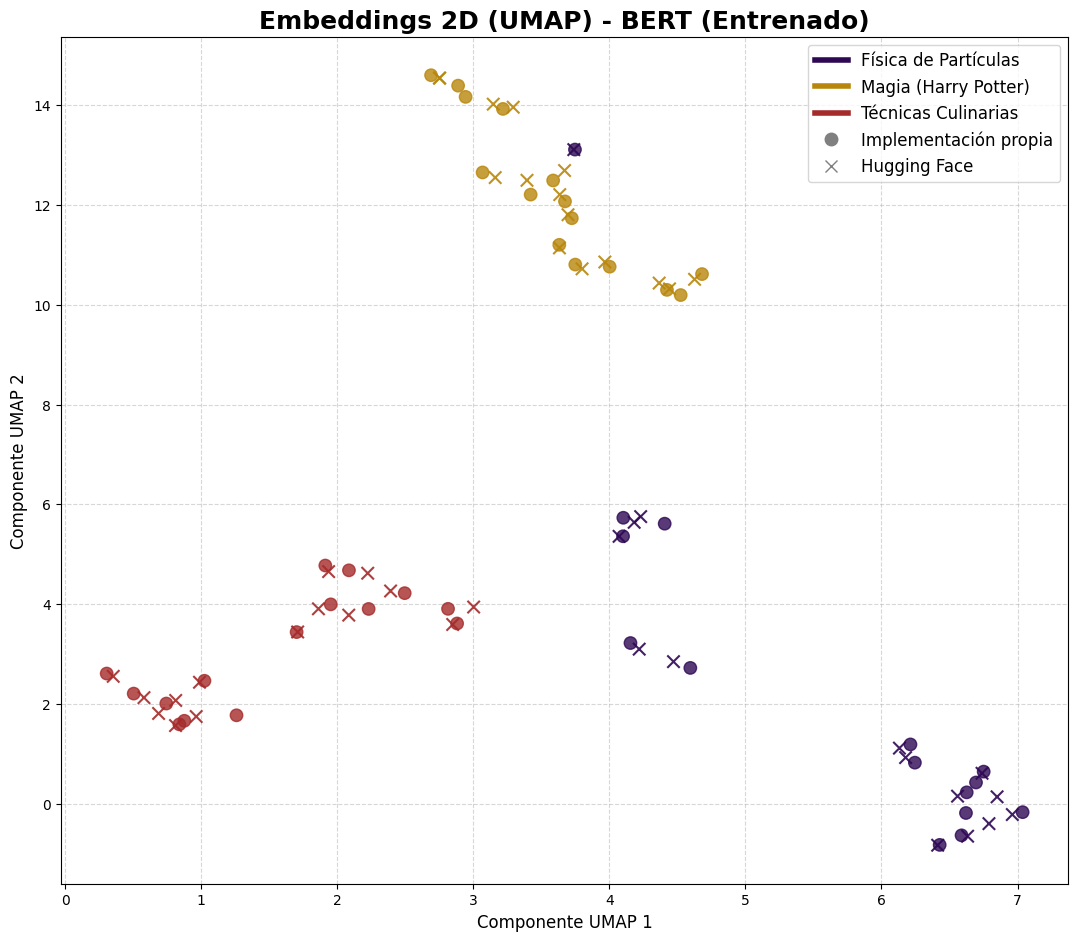

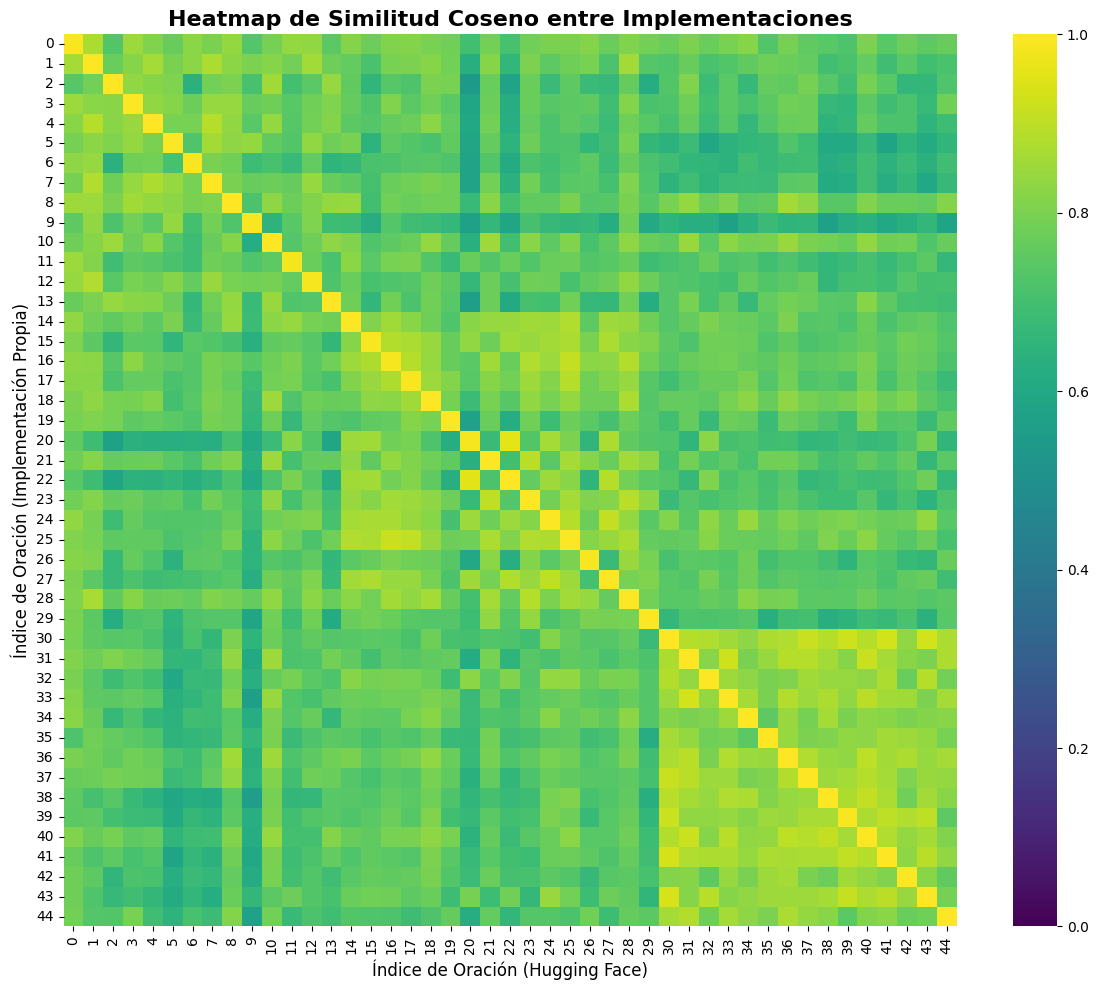

In [23]:
print("Reduciendo dimensionalidad con UMAP...")
all_embeddings = np.vstack([embeddings_sbert, embeddings_scratch])
reducer = umap.UMAP(n_neighbors=5, min_dist=0.05, n_components=2, random_state=42)
embeddings_2d_combined = reducer.fit_transform(all_embeddings)
embeddings_2d_sbert = embeddings_2d_combined[:n_sentences]
embeddings_2d_scratch = embeddings_2d_combined[n_sentences:]
embeddings_2d_scratch_raw = reducer.transform(embeddings_scratch_raw)

colors = ['#2E0854'] * 15 + ['#B8860B'] * 15 + ['#A52A2A'] * 15 # Physics, Magic, Culinary
fig1, ax1 = plt.subplots(figsize=(13, 11))

'''for i in range(n_sentences):
    p1 = embeddings_2d_sbert[i]
    p2 = embeddings_2d_scratch[i]
    ax1.plot([p1[0], p2[0]], [p1[1], p2[1]], color='gray', linewidth=0.8, alpha=0.7, zorder=1)'''

#ax1.scatter(embeddings_2d_scratch_raw[:, 0], embeddings_2d_scratch_raw[:, 1], c=colors, marker='o', s=80, alpha=0.8, label='Implementación Propia', zorder=2)
ax1.scatter(embeddings_2d_scratch[:, 0], embeddings_2d_scratch[:, 1], c=colors, marker='o', s=80, alpha=0.8, label='Implementación Propia', zorder=2)
ax1.scatter(embeddings_2d_sbert[:, 0], embeddings_2d_sbert[:, 1], c=colors, marker='x', s=80, alpha=0.9, label='Hugging Face', zorder=3)

legend_elements = [
    Line2D([0], [0], color='#2E0854', lw=4, label='Física de Partículas'),
    Line2D([0], [0], color='#B8860B', lw=4, label='Magia (Harry Potter)'),
    Line2D([0], [0], color='#A52A2A', lw=4, label='Técnicas Culinarias'),
    Line2D([0], [0], marker='o', color='gray', label='Implementación propia', markersize=9, linestyle='None'),
    Line2D([0], [0], marker='x', color='gray', label='Hugging Face', markersize=9, linestyle='None'),
]
ax1.set_title('Embeddings 2D (UMAP) - BERT (Entrenado)', fontsize=18, fontweight='bold')
ax1.set_xlabel('Componente UMAP 1', fontsize=12)
ax1.set_ylabel('Componente UMAP 2', fontsize=12)
ax1.legend(handles=legend_elements, loc='best', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
print("Gráfico 1 (Lollipop) generado.")

print("Generando heatmap de similitud...")
similarity_matrix = np.dot(embeddings_scratch, embeddings_sbert.T)
fig2, ax2 = plt.subplots(figsize=(12, 10))
sns.heatmap(similarity_matrix, cmap='viridis', ax=ax2, vmin=0, vmax=1)
ax2.set_title('Heatmap de Similitud Coseno entre Implementaciones', fontsize=16, fontweight='bold')
ax2.set_xlabel('Índice de Oración (Hugging Face)', fontsize=12)
ax2.set_ylabel('Índice de Oración (Implementación Propia)', fontsize=12)
print("Gráfico 2 (Heatmap) generado.")

plt.tight_layout()
plt.show()